# 04 · Análisis I: regímenes de radio


**Pregunta.** ¿La masa y la metalicidad de la estrella aportan información sobre el régimen de radio de un planeta, una vez considerado su período orbital?

**Muestra.** Planetas descubiertos por tránsito con radio, período, masa estelar y metalicidad.

**Modelos** (regresión logística multinomial; referencia = super-Tierra; predictores estandarizados):

| Modelo | Predictores |
|---|---|
| B0 (base) | `logP_z` |
| BM | `logP_z + st_mass_z` |
| BZ | `logP_z + st_met_z` |
| B1 (estelar) | `logP_z + st_mass_z + st_met_z` |

**Salidas:** tablas A1-T1 a A1-T8; figuras A1-F1 a A1-F4.

El periodo es el control porque el tamaño de un planeta depende de qué tan cerca está de la estrella, y el tránsito detecta mejor los planetas de periodo corto. Si no se incluye, podría parecer que la estrella importa solo por estar asociada al periodo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from funciones import *

usar_estilo()

## 1. Muestra

In [2]:
df = cargar_catalogo()
a1 = muestra_analisis_I(df)
a1 = estandarizar(a1, ["logP", "st_mass", "st_met"])
print(f"Planetas: {len(a1)} | estrellas anfitrionas: {a1['hostname'].nunique()}")

filas = []
for clase in CLASES_RADIO:
    d = a1[a1["clase_radio"] == clase]
    filas.append({"clase_radio": clase, "criterio": CRITERIO_CLASE[clase] + " R_Tierra",
                  "N_planetas": len(d), "porcentaje": 100 * len(d) / len(a1),
                  "pl_orbper_mediana": d["pl_orbper"].median(),
                  "st_mass_mediana": d["st_mass"].median(), "st_met_mediana": d["st_met"].median()})
tabla_muestra = guardar_tabla(
    pd.DataFrame(filas), "A1-T1", "muestra_por_regimen",
    titulo="Análisis I: composición de la muestra de planetas en tránsito por régimen de radio.",
    seccion="6.2.1", decimales=3,
    nota=f"N = {len(a1)} planetas alrededor de {a1['hostname'].nunique()} estrellas.",
    encabezados={"pl_orbper_mediana": r"$P$ med. [d]", "st_mass_mediana": r"$M_\star$ med. [$M_\odot$]",
                 "st_met_mediana": "[Fe/H] med."},
    formatos={"porcentaje": "{:.1f}", "pl_orbper_mediana": "{:.2f}"})
tabla_muestra

Planetas: 4461 | estrellas anfitrionas: 3390
Tabla A1-T1 guardada: tablas/A1-T1_muestra_por_regimen.csv


,clase_radio,criterio,N_planetas,porcentaje,pl_orbper_mediana,st_mass_mediana,st_met_mediana
0,terrestre,Rp < 1.25 R_Tierra,514,11.522,4.455,0.860,-0.010
1,supertierra,1.25 <= Rp < 2 R_Tierra,1080,24.210,6.496,0.910,0.000
2,neptuniano,2 <= Rp < 6 R_Tierra,1937,43.421,14.554,0.939,0.010
3,gigante_gaseoso,6 <= Rp < 15 R_Tierra,720,16.140,4.624,1.034,0.120
4,mayor_que_jupiter,Rp >= 15 R_Tierra,210,4.707,3.283,1.322,0.064


## 2. Exploración: propiedades estelares por régimen
Antes de ajustar modelos se prueba si las estrellas de cada régimen de planeta son distintas en masa y metalicidad.


Figura A1-F1 guardada: figuras/A1-F1_propiedades_estelares_por_regimen.png y .pdf


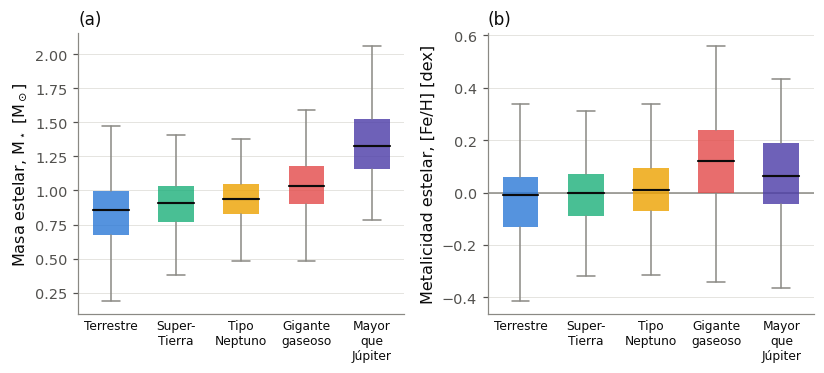

In [3]:
etiquetas = [ETIQUETA_CLASE[c].replace(" ", "\n").replace("-", "-\n") for c in CLASES_RADIO]
colores = [COLOR_CLASE[c] for c in CLASES_RADIO]

fig, ejes = plt.subplots(1, 2, figsize=(7.6, 3.5))
for ax, variable, letra in zip(ejes, ["st_mass", "st_met"], "ab"):
    cajas(ax, [a1.loc[a1["clase_radio"] == c, variable] for c in CLASES_RADIO], etiquetas, colores)
    ax.set_ylabel(EJE[variable])
    ax.tick_params(axis="x", labelsize=8, length=0, labelcolor=TINTA)
    etiqueta_panel(ax, letra)
linea_referencia(ejes[1], 0.0, eje="y")
fig.tight_layout()
guardar_figura(fig, "A1-F1", "propiedades_estelares_por_regimen",
               titulo=("Distribución de (a) la masa estelar y (b) la metalicidad de las estrellas anfitrionas por régimen de radio. "
                       "Las cajas muestran la mediana y los cuartiles; los bigotes, 1.5 veces el rango intercuartílico."),
               seccion="6.2.1")
plt.show()

Se comparan las distribuciones de la masa estelar y la metalicidad entre regímenes (Kruskal–Wallis y comparaciones por pares de Mann–Whitney). Es una comparación directa, sin controlar por el período.

Estas pruebas se utilizaron porque no suponen distribución normal. Kruskal-Wallis pregunta si los cinco regímenes difieren en conjunto. Mann-Whitney compara cada régimen con otro, para ver si son diferentes entre sí.

In [4]:
globales, pares = [], []
for variable in ["st_mass", "st_met"]:
    tabla_global, tabla_pares = kruskal_posthoc(a1, "clase_radio", variable, CLASES_RADIO)
    globales.append(tabla_global)
    pares.append(tabla_pares)

tabla_kruskal = guardar_tabla(
    pd.concat(globales, ignore_index=True).drop(columns="grupo"), "A1-T2", "kruskal_propiedades_estelares",
    titulo="Análisis I: prueba de Kruskal-Wallis de la masa estelar y la metalicidad entre los cinco regímenes de radio.",
    seccion="6.2.1", destino="anexo", encabezados={"k_grupos": "Grupos", "epsilon_cuadrado": r"$\epsilon^2$"})
tabla_posthoc = guardar_tabla(
    pd.concat(pares, ignore_index=True), "A1-T3", "comparaciones_por_pares_regimenes",
    titulo="Análisis I: comparaciones por pares (Mann-Whitney con corrección de Holm) de la masa estelar y la metalicidad entre regímenes.",
    seccion="6.2.1", destino="anexo",
    nota="La correlación biserial por rangos es positiva cuando el segundo grupo tiende a valores mayores.",
    encabezados={"grupo_0": "Grupo 0", "grupo_1": "Grupo 1", "N_0": "$N_0$", "N_1": "$N_1$", "mediana_0": "Med. 0",
                 "mediana_1": "Med. 1", "diferencia_medianas": "Dif.", "biserial_rangos": r"$r_{rb}$",
                 "significativo_holm": "Sig."})
tabla_kruskal

Tabla A1-T2 guardada: tablas/A1-T2_kruskal_propiedades_estelares.csv
Tabla A1-T3 guardada: tablas/A1-T3_comparaciones_por_pares_regimenes.csv


,variable,N,k_grupos,H,valor_p,epsilon_cuadrado
0,st_mass,4461,5,622.1373,2.510000e-133,0.1395
1,st_met,4461,5,317.2443,2.060000e-67,0.0711


Hipótesis nula: las estrellas de los cinco regímenes tienen la misma distribución de masa (o de metalicidad).
p < 0.05: se rechaza; al menos un régimen difiere de los demás.
p ≥ 0.05: no hay evidencia de diferencias.

Hay diferencias: la masa y la metalicidad de las estrellas anfitrionas difieren entre regímenes de radio. El efecto es más grande en la masa (ε² = 0.14) que en la metalicidad (ε² = 0.07).

## 3. Modelos multinomiales

La regresión logística multinomial estima la probabilidad de que un planeta pertenezca a cada régimen de radio. Para cada régimen $k$ se ajusta una ecuación que lo compara con la referencia (super-Tierra):

$$\ln\frac{P(k)}{P(\text{super-Tierra})} = \beta_{0k} + \beta_{1k}\,z_{\log P} + \beta_{2k}\,z_{M_\star} + \beta_{3k}\,z_{\mathrm{[Fe/H]}}$$

Los predictores están estandarizados, así que cada coeficiente es el efecto de aumentar una desviación estándar. $\beta > 0$ indica que ese régimen se vuelve más probable respecto a la super-Tierra.

Los cuatro modelos se ajustan sobre la misma muestra. B0 solo usa el período, BM y BZ añaden una propiedad estelar cada uno, B1 añade las dos. 

Se comparan con el pseudo-R^2 de McFadden, el AIC, el BIC y el log-loss. Si la estrella aporte información, B1 debe tener un mejor ajuste que B0.


In [5]:
clases_modelo = [CLASE_REFERENCIA] + [c for c in CLASES_RADIO if c != CLASE_REFERENCIA]
formulas = {"B0": "logP_z", "BM": "logP_z + st_mass_z", "BZ": "logP_z + st_met_z",
            "B1": "logP_z + st_mass_z + st_met_z"}
ajustes = {nombre: ajustar_multinomial(a1["clase_radio"].astype(str),
                                               matriz(a1, formula.split(" + ")), clases_modelo, nombre)
           for nombre, formula in formulas.items()}

comparacion = comparar_modelos(ajustes, formulas, referencia="B0",
                                       deltas=["AIC", "pseudo_R2", "log_loss"])
comparacion.insert(2, "N_estrellas", a1["hostname"].nunique())
comparacion = comparacion.rename(columns={"N": "N_planetas"})
tabla_comparacion = guardar_tabla(
    comparacion, "A1-T4", "comparacion_modelos_multinomiales",
    titulo="Análisis I: comparación de los modelos multinomiales. Las diferencias son respecto al modelo base B0.",
    seccion="6.2.1",
    nota="Métricas calculadas en la muestra de ajuste. pseudo-R2 de McFadden.",
    formatos={"pseudo_R2": "{:.4f}", "log_loss": "{:.4f}", "delta_pseudo_R2": "{:+.4f}", "delta_log_loss": "{:+.4f}",
              "delta_AIC": "{:+.1f}", "AIC": "{:.1f}", "BIC": "{:.1f}"})
tabla_comparacion

Tabla A1-T4 guardada: tablas/A1-T4_comparacion_modelos_multinomiales.csv


,modelo,predictores,N_estrellas,N_planetas,pseudo_R2,AIC,BIC,log_loss,delta_AIC,delta_pseudo_R2,delta_log_loss
0,B0,logP_z,3390,4461,0.0720,11548.0887,11599.3137,1.2925,0.0000,0.0000,0.0000
1,BM,logP_z + st_mass_z,3390,4461,0.1391,10722.7058,10799.5433,1.1991,-825.3829,0.0671,-0.0934
2,BZ,logP_z + st_met_z,3390,4461,0.1023,11179.5737,11256.4112,1.2503,-368.5150,0.0303,-0.0422
3,B1,logP_z + st_mass_z + st_met_z,3390,4461,0.1592,10480.5940,10583.0441,1.1711,-1067.4947,0.0872,-0.1214


- pseudo-R²: mejora de la verosimilitud (el ajuste) respecto a un modelo sin predictores.

- AIC y BIC: ajuste penalizado por el número de coeficientes, para descartar que la mejora se deba solo a la complejidad del modelo.


**Log-loss.** Para cada planeta, el modelo asigna una probabilidad a cada uno de los cinco regímenes.

El log-loss toma la probabilidad que recibió el régimen observado, $p_i$, la penaliza con $-\ln p_i$ y promedia sobre los $N$ planetas: $\text{log-loss} = -\frac{1}{N}\sum_i \ln p_i$. 

La penalización es pequeña si el modelo le dio una p alta al régimen correcto y grande si le dio una baja. Un modelo perfecto tiene log-loss igual a 0; valores más bajos indican mejores predicciones.

Como es la verosimilitud del modelo con signo negativo y dividida entre $N$, mide lo mismo que el pseudo-R² y el AIC, pero en una escala por planeta: $e^{-\text{log-loss}}$ es la probabilidad típica (media geométrica) que el modelo asigna al régimen correcto.

### Coeficientes del modelo estelar B1

Cada coeficiente es el cambio en el logaritmo de los momios (razón entre la probabilidad de que un evento ocurra y la de que no ocurra) de pertenecer al régimen indicado, frente a super-Tierra, por un aumento de una desviación estándar del predictor. RRR = exp(coeficiente).

RRR (relative risk ratio):
- RRR > 1: el régimen k se vuelve más probable frente a la super-Tierra.
- RRR = 1: no hay efecto.
- RRR < 1: el régimen k se vuelve menos probable frente a la super-Tierra.

In [6]:
B0, B1 = ajustes["B0"], ajustes["B1"]
coeficientes = B1.coeficientes(solo=["logP_z", "st_mass_z", "st_met_z"]).drop(columns=["modelo", "referencia"])
orden_clase = {c: i for i, c in enumerate(CLASES_RADIO)}
coeficientes = coeficientes.sort_values("clase_radio", key=lambda s: s.map(orden_clase), kind="stable")
tabla_coeficientes = guardar_tabla(
    coeficientes, "A1-T5", "coeficientes_multinomial_B1",
    titulo="Análisis I: coeficientes del modelo multinomial estelar B1, respecto al régimen de super-Tierra. Predictores estandarizados.",
    seccion="6.2.1",
    nota="RRR: razón de riesgo relativo, exp(coeficiente). Intervalos de confianza al 95 %.")
tabla_coeficientes

Tabla A1-T5 guardada: tablas/A1-T5_coeficientes_multinomial_B1.csv


,clase_radio,predictor,coeficiente,error_estandar,IC95_inf,IC95_sup,valor_p,RRR,RRR_IC95_inf,RRR_IC95_sup
0,terrestre,logP_z,-0.5010,0.0675,-0.6332,-0.3688,1.100000e-13,0.6059,0.5309,0.6915
1,terrestre,st_mass_z,-0.1822,0.0608,-0.3013,-0.0630,2.730000e-03,0.8335,0.7399,0.9389
2,terrestre,st_met_z,-0.1387,0.0554,-0.2473,-0.0302,1.230000e-02,0.8705,0.7809,0.9703
3,neptuniano,logP_z,0.8360,0.0479,0.7420,0.9299,4.170000e-68,2.3071,2.1002,2.5343
4,neptuniano,st_mass_z,0.0834,0.0480,-0.0105,0.1774,8.180000e-02,1.0870,0.9895,1.1941
5,neptuniano,st_met_z,0.2295,0.0432,0.1449,0.3141,1.060000e-07,1.2580,1.1559,1.3690
6,gigante_gaseoso,logP_z,0.2649,0.0597,0.1479,0.3819,9.090000e-06,1.3033,1.1594,1.4651
7,gigante_gaseoso,st_mass_z,0.6207,0.0629,0.4974,0.7439,5.660000e-23,1.8602,1.6445,2.1042
8,gigante_gaseoso,st_met_z,0.7636,0.0580,0.6499,0.8773,1.470000e-39,2.1460,1.9153,2.4045
9,mayor_que_jupiter,logP_z,-1.6005,0.1516,-1.8976,-1.3034,4.650000e-26,0.2018,0.1499,0.2716


Cada fila mide el efecto de una variable sobre un régimen, comparado con la super-Tierra.

- **Coeficiente:** dirección y fuerza del efecto. Positivo = el régimen se vuelve más probable al aumentar la variable; negativo = menos probable; cero = sin efecto.
- **Error estándar:** incertidumbre del coeficiente.
- **Intervalo de confianza al 95 %:** rango de valores compatibles con los datos. Si no incluye el cero, el efecto es significativo.
- **Valor p:** probabilidad de ver un efecto así por azar si en realidad no existiera. Significativo si es menor que 0.05.
- **RRR:** el coeficiente en escala más intuitiva, $e^{\text{coeficiente}}$. Indica por cuánto se multiplica el cociente de probabilidades del régimen frente a la super-Tierra por cada desviación estándar (1 = sin efecto).

**Ejemplo.** Gigante gaseoso, metalicidad: coeficiente 0.76, intervalo de 0.65 a 0.88, RRR = 2.15. Una desviación estándar más de metalicidad multiplica por 2.15 el cociente de probabilidades gigante gaseoso / super-Tierra, y el efecto es significativo.

## 4. ¿En qué regímenes aporta información la estrella?

Para cada régimen se calcula el *log-loss* medio de sus planetas bajo cada modelo. La **ganancia** es la reducción del *log-loss* respecto a B0: valores positivos indican que el modelo asigna mayor probabilidad al régimen observado.

In [7]:
perdida = pd.DataFrame({nombre: log_loss_por_clase(a) for nombre, a in ajustes.items()}).loc[CLASES_RADIO]
ganancia = pd.DataFrame({
    "clase_radio": CLASES_RADIO,
    "N_planetas": [int((a1["clase_radio"] == c).sum()) for c in CLASES_RADIO],
    "log_loss_B0": perdida["B0"].to_numpy(),
    "ganancia_st_mass": (perdida["B0"] - perdida["BM"]).to_numpy(),
    "ganancia_st_met": (perdida["B0"] - perdida["BZ"]).to_numpy(),
    "ganancia_ambas": (perdida["B0"] - perdida["B1"]).to_numpy(),
    "ganancia_st_mass_dado_st_met": (perdida["BZ"] - perdida["B1"]).to_numpy(),
    "ganancia_st_met_dado_st_mass": (perdida["BM"] - perdida["B1"]).to_numpy(),
})
ganancia["predictor_dominante"] = np.where(ganancia["ganancia_st_mass"] > ganancia["ganancia_st_met"], "st_mass", "st_met")
ganancia["AUC_B0"] = auc_por_clase(B0).loc[CLASES_RADIO].to_numpy()
ganancia["AUC_B1"] = auc_por_clase(B1).loc[CLASES_RADIO].to_numpy()
tabla_ganancia = guardar_tabla(
    ganancia, "A1-T6", "ganancia_de_informacion_por_regimen",
    titulo="Análisis I: reducción del log-loss de cada régimen al añadir la masa estelar, la metalicidad o ambas al modelo base.",
    seccion="6.2.1",
    nota="Ganancia = log-loss de B0 menos log-loss del modelo ampliado, entre los planetas del régimen. AUC de cada régimen frente al resto (descriptivo).",
    encabezados={"log_loss_B0": "log-loss B0", "ganancia_st_mass": r"Gan. $M_\star$", "ganancia_st_met": "Gan. [Fe/H]",
                 "ganancia_ambas": "Gan. ambas", "ganancia_st_mass_dado_st_met": r"$M_\star \mid$ [Fe/H]",
                 "ganancia_st_met_dado_st_mass": r"[Fe/H] $\mid M_\star$", "predictor_dominante": "Dominante",
                 "AUC_B0": "AUC B0", "AUC_B1": "AUC B1"})
tabla_ganancia

Tabla A1-T6 guardada: tablas/A1-T6_ganancia_de_informacion_por_regimen.csv


,clase_radio,N_planetas,log_loss_B0,ganancia_st_mass,ganancia_st_met,ganancia_ambas,ganancia_st_mass_dado_st_met,ganancia_st_met_dado_st_mass,predictor_dominante,AUC_B0,AUC_B1
0,terrestre,514,1.9627,0.0988,0.0775,0.1364,0.0589,0.0376,st_mass,0.6890,0.7493
1,supertierra,1080,1.3873,0.0432,0.0295,0.0596,0.0300,0.0163,st_mass,0.5677,0.6461
2,neptuniano,1937,0.7146,0.0113,0.0029,0.0151,0.0122,0.0038,st_mass,0.7440,0.7514
3,gigante_gaseoso,720,1.8571,0.0883,0.1521,0.1915,0.0394,0.1032,st_met,0.5465,0.6986
4,mayor_que_jupiter,210,2.5603,1.1134,0.0072,1.1441,1.1369,0.0307,st_mass,0.8125,0.9454


Figura A1-F2 guardada: figuras/A1-F2_ganancia_de_informacion_por_regimen.png y .pdf


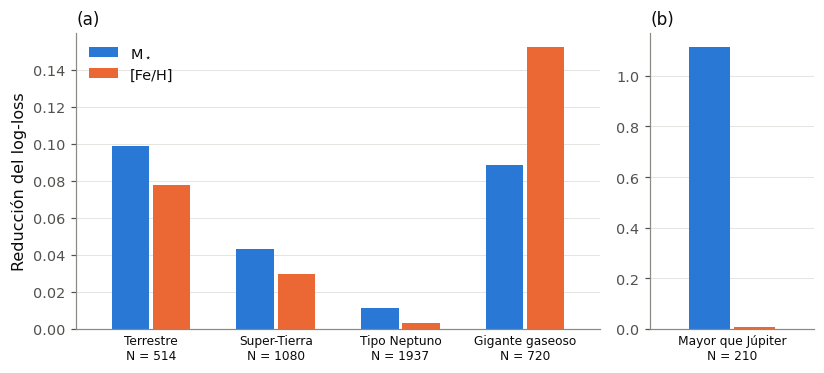

In [8]:
ancho = 0.30
fig, ejes = plt.subplots(1, 2, figsize=(7.6, 3.5), gridspec_kw={"width_ratios": [4, 1.25]})
for ax, clases, letra in [(ejes[0], CLASES_RADIO[:4], "a"), (ejes[1], CLASES_RADIO[4:], "b")]:
    d = ganancia.set_index("clase_radio").loc[clases]
    x = np.arange(len(clases))
    ax.bar(x - ancho / 2 - 0.015, d["ganancia_st_mass"], ancho, color=COLOR_MASA_ESTELAR, label=r"$M_\star$")
    ax.bar(x + ancho / 2 + 0.015, d["ganancia_st_met"], ancho, color=COLOR_METALICIDAD, label="[Fe/H]")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{ETIQUETA_CLASE[c]}\nN = {n}" for c, n in zip(clases, d["N_planetas"])], fontsize=8)
    ax.tick_params(axis="x", length=0, labelcolor=TINTA)
    ax.grid(axis="x", visible=False)
    ax.set_xlim(-0.6, len(clases) - 0.4)
    etiqueta_panel(ax, letra)
ejes[0].set_ylabel("Reducción del log-loss")
ejes[0].legend(loc="upper left")
fig.tight_layout()
guardar_figura(fig, "A1-F2", "ganancia_de_informacion_por_regimen",
               titulo=("Reducción del log-loss de cada régimen de radio al añadir al modelo base la masa estelar o la metalicidad. "
                       "(a) Regímenes de terrestre a gigante gaseoso. (b) Planetas mayores que Júpiter, en escala propia."),
               seccion="6.2.1", nota="Los dos paneles tienen escalas verticales distintas.")
plt.show()

### Ganancia de información por régimen

Aquí se revisa en qué tipo de planeta ayuda más cada propiedad de la estrella.

Cómo se calcula:

- Se toman solo los planetas de un régimen (por ejemplo, los 720 gigantes gaseosos).
- Se calcula el log-loss de ese grupo con el modelo base B0, que solo usa el período.
- Se calcula otra vez con BM (período + masa estelar) y con BZ (período + metalicidad).
- La ganancia es la resta: log-loss de B0 menos log-loss del otro modelo.

Si la ganancia es grande, esa variable ayuda bastante a predecir ese régimen. Si es casi cero, no aporta.



## 5. Probabilidades predichas

Resumen del modelo B1: probabilidad de cada régimen al variar una propiedad estelar, con el período y la otra propiedad fijos en la mediana de la muestra. No son fracciones observadas.

Figura A1-F3 guardada: figuras/A1-F3_probabilidades_predichas_por_regimen.png y .pdf


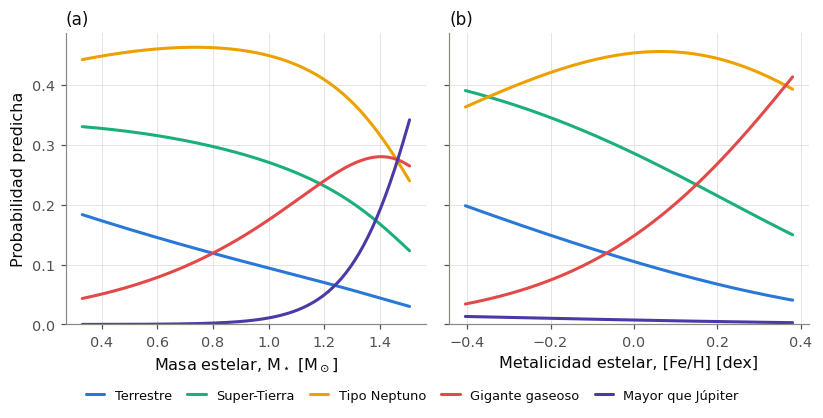

In [9]:
def rejilla_B1(variable, valores):
    rejilla = pd.DataFrame({v: a1[v].median() for v in ["logP", "st_mass", "st_met"]}, index=range(len(valores)))
    rejilla[variable] = valores
    rejilla = estandarizar(rejilla, ["logP", "st_mass", "st_met"], referencia=a1)
    prob = pd.DataFrame(B1.predecir(matriz(rejilla, ["logP_z", "st_mass_z", "st_met_z"])), columns=clases_modelo)
    return pd.concat([rejilla[[variable]], prob[CLASES_RADIO]], axis=1)

curvas = {v: rejilla_B1(v, np.linspace(a1[v].quantile(0.02), a1[v].quantile(0.98), 150)) for v in ["st_mass", "st_met"]}
curvas["st_mass"].to_csv(DATOS_PROCESADOS / "A1_probabilidades_predichas_vs_st_mass.csv", index=False)
curvas["st_met"].to_csv(DATOS_PROCESADOS / "A1_probabilidades_predichas_vs_st_met.csv", index=False)

fig, ejes = plt.subplots(1, 2, figsize=(7.6, 3.6), sharey=True)
for ax, variable, letra in zip(ejes, ["st_mass", "st_met"], "ab"):
    for clase in CLASES_RADIO:
        ax.plot(curvas[variable][variable], curvas[variable][clase], color=COLOR_CLASE[clase],
                label=ETIQUETA_CLASE[clase])
    ax.set_xlabel(EJE[variable])
    ax.set_ylim(0, None)
    etiqueta_panel(ax, letra)
ejes[0].set_ylabel(EJE["prob"])
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=5, fontsize=8.5,
           bbox_to_anchor=(0.5, -0.06), columnspacing=1.2, handlelength=1.4)
fig.tight_layout()
guardar_figura(fig, "A1-F3", "probabilidades_predichas_por_regimen",
               titulo=("Probabilidad predicha de cada régimen de radio según el modelo multinomial B1, en función de (a) la masa "
                       "estelar y (b) la metalicidad. El período orbital y la otra propiedad estelar se fijan en su mediana."),
               seccion="6.2.1")
plt.show()

### Probabilidades predichas por el modelo B1

Estas curvas no son planetas contados, son predicciones del modelo B1.

Cómo se obtienen:

- Se arma una lista de estrellas ficticias que solo cambian en una propiedad (la masa en el panel a, la metalicidad en el panel b).
- El período y la otra propiedad se dejan fijos en la mediana de la muestra.
- Para cada estrella de la lista, el modelo calcula la probabilidad de cada régimen con los coeficientes de la tabla A1-T5.
- Cada curva une esas probabilidades para un régimen. En cualquier punto, las cinco suman 1.


- Con más masa estelar bajan los terrestres y las super-Tierras y suben los gigantes gaseosos. Por encima de 1.2 M☉ suben mucho los mayores que Júpiter.
- Con más metalicidad los gigantes gaseosos pasan de cerca de 4 % a 40 %, y bajan los terrestres y las super-Tierras.
- La metalicidad casi no cambia la probabilidad de los mayores que Júpiter.

Estas probabilidades valen para planetas detectados por tránsito con período cercano a la mediana (unos 9 días). No son frecuencias reales de planetas.

In [10]:
representativas = []
for variable in ["st_mass", "st_met"]:
    percentiles = a1[variable].quantile([0.2, 0.5, 0.8])
    r = rejilla_B1(variable, percentiles.to_numpy()).rename(columns={variable: "valor"})
    r.insert(0, "percentil", ["P20", "P50", "P80"])
    r.insert(0, "variable", variable)
    representativas.append(r)
tabla_representativas = guardar_tabla(
    pd.concat(representativas, ignore_index=True), "A1-T7", "probabilidades_predichas_representativas",
    titulo="Análisis I: probabilidad predicha de cada régimen en los percentiles 20, 50 y 80 de la masa estelar y de la metalicidad.",
    seccion="6.2.1", destino="anexo",
    nota="Modelo B1; las demás variables se fijan en su mediana.",
    encabezados={"percentil": "Percentil", "valor": "Valor", **{c: ETIQUETA_CLASE[c] for c in CLASES_RADIO}})
tabla_representativas

Tabla A1-T7 guardada: tablas/A1-T7_probabilidades_predichas_representativas.csv


,variable,percentil,valor,terrestre,supertierra,neptuniano,gigante_gaseoso,mayor_que_jupiter
0,st_mass,P20,0.7770,0.1218,0.2997,0.4629,0.1137,0.0019
1,st_mass,P50,0.9450,0.1009,0.2791,0.4550,0.1579,0.0071
2,st_mass,P80,1.1100,0.0810,0.2514,0.4319,0.2105,0.0253
3,st_met,P20,-0.1000,0.1264,0.3175,0.4415,0.1059,0.0087
4,st_met,P50,0.0200,0.1009,0.2791,0.4550,0.1579,0.0071
5,st_met,P80,0.1445,0.0770,0.2352,0.4521,0.2303,0.0055


In [11]:
X_C0 = base_spline(a1["logP_z"], nudos_spline(a1["logP_z"], gl=5), "sP")
X_C0.insert(0, "const", 1.0)
X_C1 = X_C0.assign(st_mass_z=a1["st_mass_z"], st_met_z=a1["st_met_z"])
X_C2 = pd.concat([X_C0,
                  base_spline(a1["st_mass_z"], nudos_spline(a1["st_mass_z"], gl=4), "sM"),
                  base_spline(a1["st_met_z"], nudos_spline(a1["st_met_z"], gl=4), "sZ")], axis=1)
continuos = {"C0": ajustar_lineal(a1["logRp"], X_C0, a1["hostname"], "C0"),
             "C1": ajustar_lineal(a1["logRp"], X_C1, a1["hostname"], "C1"),
             "C2": ajustar_lineal(a1["logRp"], X_C2, a1["hostname"], "C2")}
formulas_C = {"C0": "s(logP_z)", "C1": "s(logP_z) + st_mass_z + st_met_z",
              "C2": "s(logP_z) + s(st_mass_z) + s(st_met_z)"}
comparacion_C = comparar_modelos(continuos, formulas_C, referencia="C0", deltas=["R2", "AIC", "RMSE"])
coef_C1 = continuos["C1"].coeficientes(solo=["st_mass_z", "st_met_z"])
texto_coef = "; ".join(f"{fila.predictor}: {fila.coeficiente:.3f} [{fila.IC95_inf:.3f}, {fila.IC95_sup:.3f}]"
                       for fila in coef_C1.itertuples())
tabla_continuo = guardar_tabla(
    comparacion_C.rename(columns={"N": "N_planetas"}), "A1-T8", "verificacion_radio_continuo",
    titulo="Análisis I: verificación con el radio como variable continua. Respuesta: logaritmo del radio planetario.",
    seccion="6.2.3",
    nota=f"s() denota un spline cúbico. Coeficientes estandarizados en C1 (IC 95 %, errores agrupados por estrella): {texto_coef}.",
    formatos={"delta_AIC": "{:+.1f}", "delta_R2": "{:+.4f}", "delta_RMSE": "{:+.4f}"})
display(tabla_continuo)
coef_C1

Tabla A1-T8 guardada: tablas/A1-T8_verificacion_radio_continuo.csv


,modelo,predictores,N_planetas,R2,R2_ajustado,AIC,BIC,RMSE,MAE,delta_R2,delta_AIC,delta_RMSE
0,C0,s(logP_z),4461,0.0657,0.0647,3350.8600,3389.2787,0.3518,0.2776,0.0000,0.0000,0.0000
1,C1,s(logP_z) + st_mass_z + st_met_z,4461,0.2274,0.2262,2507.2899,2558.5150,0.3199,0.2542,0.1617,-843.5700,-0.0319
2,C2,s(logP_z) + s(st_mass_z) + s(st_met_z),4461,0.2645,0.2623,2299.7847,2389.4285,0.3121,0.2427,0.1988,-1051.0752,-0.0397


,modelo,predictor,coeficiente,error_estandar,IC95_inf,IC95_sup,valor_p
0,C1,st_mass_z,0.122542,0.005319,0.112117,0.132968,1.966789e-117
1,C1,st_met_z,0.054981,0.006150,0.042926,0.067035,3.913621e-19


Figura A1-F4 guardada: figuras/A1-F4_radio_continuo_observado_vs_predicho.png y .pdf


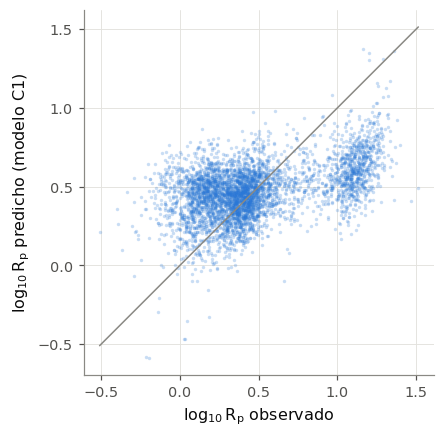

In [12]:
fig, ax = plt.subplots(figsize=(4.6, 4.3))
ax.scatter(a1["logRp"], continuos["C1"].ajustados, s=5, color=COLOR_UNICO, alpha=0.25, linewidths=0)
limites = [a1["logRp"].min(), a1["logRp"].max()]
ax.plot(limites, limites, color=GRIS, linewidth=1.0)
ax.set_xlabel(r"$\log_{10} R_p$ observado")
ax.set_ylabel(r"$\log_{10} R_p$ predicho (modelo C1)")
ax.set_aspect("equal")
guardar_figura(fig, "A1-F4", "radio_continuo_observado_vs_predicho",
               titulo="Radio observado frente al predicho por el modelo continuo C1. La línea gris es la identidad.",
               seccion="6.2.3", destino="anexo")
plt.show()

## Lectura de los resultados

- Añadir la masa estelar y la metalicidad al modelo base mejora el ajuste en todos los criterios (tabla A1-T4).
- La información estelar no se reparte igual entre regímenes (tabla A1-T6, figura A1-F2): la masa estelar domina en los planetas terrestres, las super-Tierras y, sobre todo, los mayores que Júpiter; la metalicidad domina en los gigantes gaseosos; los planetas tipo Neptuno casi no ganan información.
- El modelo con el radio continuo confirma que la señal no depende de la división en clases (tabla A1-T8).
- Las métricas son de la muestra de ajuste: describen el ajuste y no demuestran capacidad predictiva fuera de muestra.